Dataset shape: (569, 31)

Class distribution (0=Benign, 1=Malignant):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



Training: (341, 30)
Validation: (114, 30)
Testing: (114, 30)

Training: ANN 1 - Shallow [30, 16, 1]
Epoch  25: Train loss=0.2035, Val loss=0.1848
Epoch  50: Train loss=0.1367, Val loss=0.1167
Epoch  75: Train loss=0.1094, Val loss=0.0905
Epoch 100: Train loss=0.0953, Val loss=0.0769
Epoch 125: Train loss=0.0865, Val loss=0.0688
Epoch 150: Train loss=0.0802, Val loss=0.0636
Epoch 175: Train loss=0.0753, Val loss=0.0601
Epoch 200: Train loss=0.0712, Val loss=0.0578

Training: ANN 2 - Deep [30, 32, 16, 1]
Epoch  25: Train loss=0.1837, Val loss=0.1488
Epoch  50: Train loss=0.1180, Val loss=0.0970
Epoch  75: Train loss=0.0922, Val loss=0.0768
Epoch 100: Train loss=0.0773, Val loss=0.0668
Epoch 125: Train loss=0.0667, Val loss=0.0615
Epoch 150: Train loss=0.0586, Val loss=0.0587
Epoch 175: Train loss=0.0521, Val loss=0.0562
Epoch 200: Train loss=0.0464, Val loss=0.0545

Training: ANN 3 - Deeper [30, 64, 32, 16, 1]
Epoch  25: Train loss=0.1216, Val loss=0.0907
Epoch  50: Train loss=0.0849, V

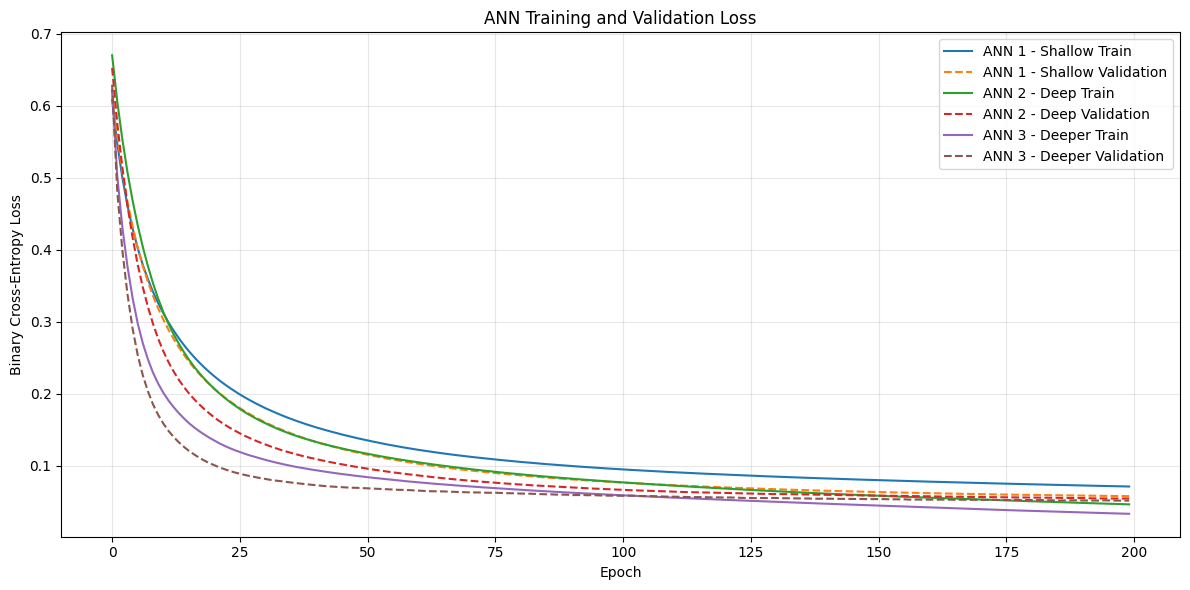


TEST SET MODEL COMPARISON


,Model,Accuracy,Precision,Malignant Recall,F1 Score
0,ANN 1 - Shallow,0.9737,1.0,0.9286,0.9630
1,ANN 2 - Deep,0.9825,1.0,0.9524,0.9756
2,ANN 3 - Deeper,0.9825,1.0,0.9524,0.9756


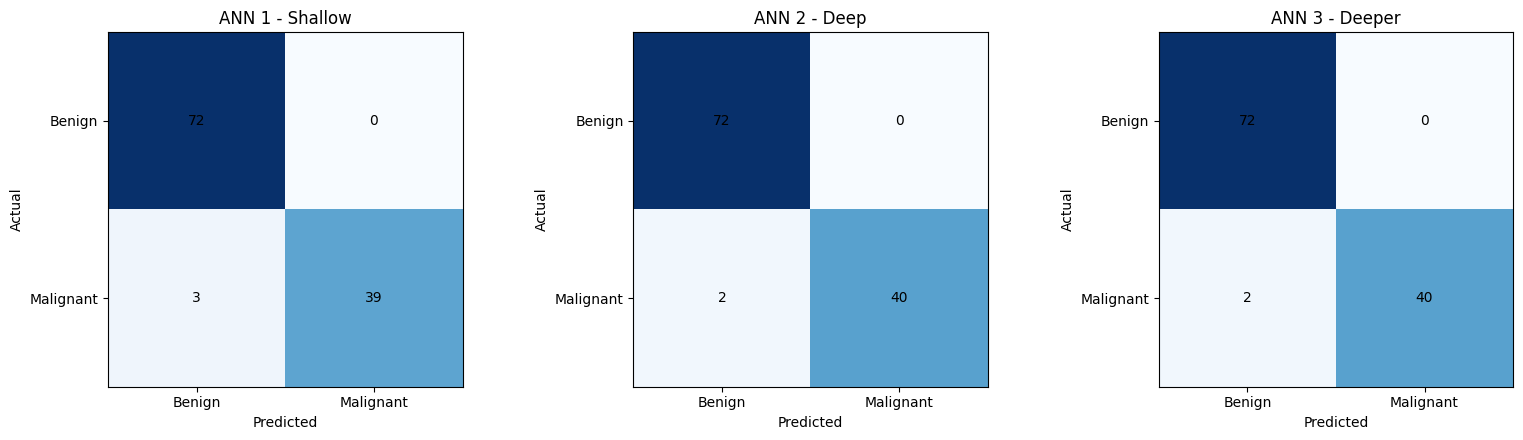


ANN 1 - Shallow
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


ANN 2 - Deep
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


ANN 3 - Deeper
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98    

,Model,Validation Recall,Validation F1
0,ANN 1 - Shallow,0.9535,0.9762
1,ANN 3 - Deeper,0.9535,0.9762
2,ANN 2 - Deep,0.9302,0.9639


Selected model: ANN 1 - Shallow

SAMPLE TEST PREDICTION
Predicted: Benign
Estimated malignant probability: 1.27%
Actual: Benign

Saved ann_model_comparison.csv
PROJECT COMPLETED SUCCESSFULLY!


In [ ]:
# ============================================================
# BREAST CANCER CLASSIFICATION USING MULTIPLE ANN MODELS

# NumPy + Pandas + Matplotlib + Scikit-learn
# 0 = Benign, 1 = Malignant
# ============================================================

!pip -q install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

np.random.seed(42)

# 1. LOAD DATASET
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = (data.target == 0).astype(int)

print("Dataset shape:", df.shape)
print("\nClass distribution (0=Benign, 1=Malignant):")
print(df["target"].value_counts())
display(df.head())

# Optional: save dataset
df.to_csv("breast_cancer.csv", index=False)

# 2. SPLIT DATA: 60% TRAIN, 20% VALIDATION, 20% TEST
X = df.drop(columns="target").to_numpy(dtype=float)
y = df["target"].to_numpy(dtype=float).reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42,
    stratify=y_temp
)

# Standardize using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# 3. NEURAL NETWORK IMPLEMENTED WITH NUMPY
class NeuralNetwork:
    def __init__(self, layers, lr=0.01, seed=42):
        self.lr = lr
        self.rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        self.train_loss, self.val_loss = [], []

        for i in range(len(layers) - 1):
            fan_in, fan_out = layers[i], layers[i+1]
            scale = np.sqrt(
                2 / fan_in if i < len(layers)-2
                else 1 / fan_in
            )
            self.W.append(
                self.rng.standard_normal((fan_in, fan_out)) * scale
            )
            self.b.append(np.zeros((1, fan_out)))

    @staticmethod
    def sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    @staticmethod
    def loss_fn(y, p):
        p = np.clip(p, 1e-12, 1-1e-12)
        return float(-np.mean(
            y*np.log(p) + (1-y)*np.log(1-p)
        ))

    def forward(self, X):
        A = [X]
        Z = []

        for i in range(len(self.W)-1):
            z = A[-1] @ self.W[i] + self.b[i]
            Z.append(z)
            A.append(np.maximum(0, z))

        z = A[-1] @ self.W[-1] + self.b[-1]
        Z.append(z)
        A.append(self.sigmoid(z))

        return A, Z

    def predict_proba(self, X):
        return self.forward(X)[0][-1]

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def train(self, X, y, Xv, yv, epochs=200,
              batch_size=32, patience=25):

        best_loss = np.inf
        best_W, best_b = None, None
        wait = 0

        for epoch in range(epochs):
            order = self.rng.permutation(len(X))

            for start in range(0, len(X), batch_size):
                idx = order[start:start+batch_size]
                xb, yb = X[idx], y[idx]
                m = len(xb)

                A, Z = self.forward(xb)
                delta = A[-1] - yb
                dW = [None] * len(self.W)
                db = [None] * len(self.b)

                for i in reversed(range(len(self.W))):
                    dW[i] = A[i].T @ delta / m
                    db[i] = np.mean(delta, axis=0, keepdims=True)

                    if i > 0:
                        delta = (
                            delta @ self.W[i].T
                        ) * (Z[i-1] > 0)

                for i in range(len(self.W)):
                    self.W[i] -= self.lr * dW[i]
                    self.b[i] -= self.lr * db[i]

            tl = self.loss_fn(y, self.predict_proba(X))
            vl = self.loss_fn(yv, self.predict_proba(Xv))
            self.train_loss.append(tl)
            self.val_loss.append(vl)

            if vl < best_loss - 1e-5:
                best_loss = vl
                best_W = [w.copy() for w in self.W]
                best_b = [b.copy() for b in self.b]
                wait = 0
            else:
                wait += 1

            if (epoch+1) % 25 == 0:
                print(
                    f"Epoch {epoch+1:3d}: "
                    f"Train loss={tl:.4f}, Val loss={vl:.4f}"
                )

            if wait >= patience:
                print("Early stopping at epoch", epoch+1)
                break

        if best_W is not None:
            self.W, self.b = best_W, best_b

        return self

# 4. DEFINE AND TRAIN THREE ANN ARCHITECTURES
input_size = X_train.shape[1]

architectures = {
    "ANN 1 - Shallow": [input_size, 16, 1],
    "ANN 2 - Deep": [input_size, 32, 16, 1],
    "ANN 3 - Deeper": [input_size, 64, 32, 16, 1]
}

models = {}

for i, (name, layers) in enumerate(architectures.items()):
    print("\n" + "="*55)
    print("Training:", name, layers)

    model = NeuralNetwork(layers, lr=0.01, seed=42+i)
    model.train(
        X_train, y_train, X_val, y_val,
        epochs=200, batch_size=32, patience=25
    )
    models[name] = model

# 5. PLOT TRAINING AND VALIDATION LOSS
plt.figure(figsize=(12, 6))

for name, model in models.items():
    plt.plot(model.train_loss, label=name+" Train")
    plt.plot(model.val_loss, "--", label=name+" Validation")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 6. EVALUATE MODELS ON THE TEST SET
y_true = y_test.ravel().astype(int)
results = {}
rows = []

for name, model in models.items():
    pred = model.predict(X_test).ravel().astype(int)
    results[name] = pred

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Malignant Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, pred, zero_division=0
        )
    })

results_df = pd.DataFrame(rows)

print("\nTEST SET MODEL COMPARISON")
display(results_df.round(4))

# 7. CONFUSION MATRICES
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, pred) in zip(axes, results.items()):
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Benign", "Malignant"])
    ax.set_yticklabels(["Benign", "Malignant"])

    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]),
                    ha="center", va="center")

plt.tight_layout()
plt.show()

# 8. CLASSIFICATION REPORTS
for name, pred in results.items():
    print("\n", "="*50)
    print(name)
    print(classification_report(
        y_true, pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))

# 9. SELECT MODEL USING VALIDATION SET
val_rows = []

for name, model in models.items():
    pred = model.predict(X_val).ravel().astype(int)
    actual = y_val.ravel().astype(int)

    val_rows.append({
        "Model": name,
        "Validation Recall": recall_score(
            actual, pred, zero_division=0
        ),
        "Validation F1": f1_score(
            actual, pred, zero_division=0
        )
    })

val_df = pd.DataFrame(val_rows).sort_values(
    ["Validation Recall", "Validation F1"],
    ascending=False
).reset_index(drop=True)

print("\nVALIDATION-BASED MODEL SELECTION")
display(val_df.round(4))

best_name = val_df.iloc[0]["Model"]
best_model = models[best_name]
print("Selected model:", best_name)

# 10. SAMPLE PREDICTION
sample = X_test[0:1]
prob = float(best_model.predict_proba(sample)[0, 0])
predicted = int(prob >= 0.5)
actual = int(y_test[0, 0])

print("\nSAMPLE TEST PREDICTION")
print("Predicted:", "Malignant" if predicted else "Benign")
print(f"Estimated malignant probability: {prob:.2%}")
print("Actual:", "Malignant" if actual else "Benign")

# 11. SAVE MODEL COMPARISON
results_df.to_csv("ann_model_comparison.csv", index=False)
print("\nSaved ann_model_comparison.csv")
print("PROJECT COMPLETED SUCCESSFULLY!")

# Educational demonstration only; not for clinical diagnosis.